In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("https://raw.githubusercontent.com/25k-0116Haram/GlucoGuide-AI/refs/heads/main/data/raw/diabetes_data.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
print("\nFirst 5 Rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
df.info()


First 5 Rows:
   Age Gender Polyuria Polydipsia sudden weight loss weakness Polyphagia  \
0   40   Male       No        Yes                 No      Yes         No   
1   58   Male       No         No                 No      Yes         No   
2   41   Male      Yes         No                 No      Yes        Yes   
3   45   Male       No         No                Yes      Yes        Yes   
4   60   Male      Yes        Yes                Yes      Yes        Yes   

  Genital thrush visual blurring Itching Irritability delayed healing  \
0             No              No     Yes           No             Yes   
1             No             Yes      No           No              No   
2             No              No     Yes           No             Yes   
3            Yes              No     Yes           No             Yes   
4             No             Yes     Yes          Yes             Yes   

  partial paresis muscle stiffness Alopecia Obesity     class  
0              No        

In [4]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nTarget Class Distribution:")
print(df["class"].value_counts())

Missing Values:
Age                   0
Gender                0
Polyuria              0
Polydipsia            0
sudden weight loss    0
weakness              0
Polyphagia            0
Genital thrush        0
visual blurring       0
Itching               0
Irritability          0
delayed healing       0
partial paresis       0
muscle stiffness      0
Alopecia              0
Obesity               0
class                 0
dtype: int64

Duplicate Records:
269

Target Class Distribution:
class
Positive    320
Negative    200
Name: count, dtype: int64


In [5]:

df.columns = df.columns.str.strip()

for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()

df.drop_duplicates(inplace=True)

df['Age'] = pd.to_numeric(df['Age'], errors='coerce')

print("Dataset Shape:", df.shape)
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())


Dataset Shape: (251, 17)
Missing Values: 0
Duplicate Rows: 0


C:\Users\S.K\AppData\Local\Temp\ipykernel_644\4114081689.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:
C:\Users\S.K\AppData\Local\Temp\ipykernel_644\4114081689.py:6: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(inplace=True)


In [6]:
df_encoded = pd.get_dummies(df, drop_first=True, dtype=int)

print("Encoded Dataset:")
display(df_encoded.head())

print("New Dataset Shape:", df_encoded.shape)

Encoded Dataset:


,Age,Gender_Male,Polyuria_Yes,Polydipsia_Yes,sudden weight loss_Yes,weakness_Yes,Polyphagia_Yes,Genital thrush_Yes,visual blurring_Yes,Itching_Yes,Irritability_Yes,delayed healing_Yes,partial paresis_Yes,muscle stiffness_Yes,Alopecia_Yes,Obesity_Yes,class_Positive
0,40,1,0,1,0,1,0,0,0,1,0,1,0,1,1,1,1
1,58,1,0,0,0,1,0,0,1,0,0,0,1,0,1,0,1
2,41,1,1,0,0,1,1,0,0,1,0,1,0,1,1,0,1
3,45,1,0,0,1,1,1,1,0,1,0,1,0,0,0,0,1
4,60,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1


New Dataset Shape: (251, 17)


In [7]:
X = df_encoded.drop('class_Positive', axis=1)
y = df_encoded['class_Positive']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (251, 16)
Target Shape: (251,)


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (200, 16)
Testing Data: (51, 16)


In [9]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train, y_train)

y_pred_lr = lr_model.predict(X_test)

print("Logistic Regression Accuracy:", lr_model.score(X_test, y_test))

Logistic Regression Accuracy: 0.8235294117647058


In [10]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)

print("Decision Tree Accuracy:", dt_model.score(X_test, y_test))

Decision Tree Accuracy: 0.8235294117647058


In [11]:
print("Logistic Regression Training Accuracy:",
      lr_model.score(X_train, y_train))

print("Decision Tree Training Accuracy:",
      dt_model.score(X_train, y_train))

Logistic Regression Training Accuracy: 0.925
Decision Tree Training Accuracy: 1.0


In [12]:
from sklearn.metrics import accuracy_score, classification_report

print("Logistic Regression")
print(classification_report(y_test, y_pred_lr))

print("Decision Tree")
print(classification_report(y_test, y_pred_dt))

Logistic Regression
              precision    recall  f1-score   support

           0       0.67      0.88      0.76        16
           1       0.93      0.80      0.86        35

    accuracy                           0.82        51
   macro avg       0.80      0.84      0.81        51
weighted avg       0.85      0.82      0.83        51

Decision Tree
              precision    recall  f1-score   support

           0       0.65      0.94      0.77        16
           1       0.96      0.77      0.86        35

    accuracy                           0.82        51
   macro avg       0.81      0.85      0.81        51
weighted avg       0.87      0.82      0.83        51



In [13]:
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_dt)
    ]
})

display(results)

,Model,Accuracy
0,Logistic Regression,0.823529
1,Decision Tree,0.823529


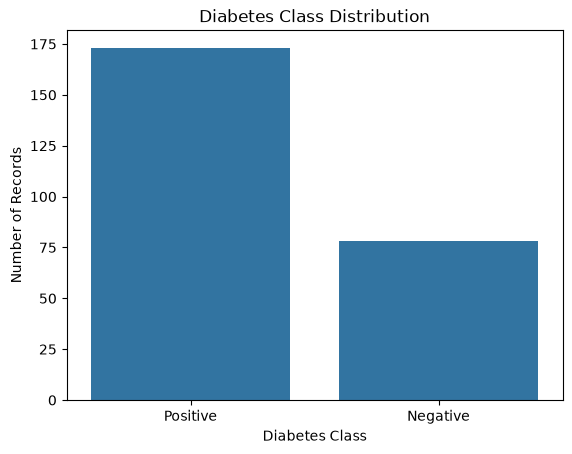

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x='class')
plt.title("Diabetes Class Distribution")
plt.xlabel("Diabetes Class")
plt.ylabel("Number of Records")
plt.show()

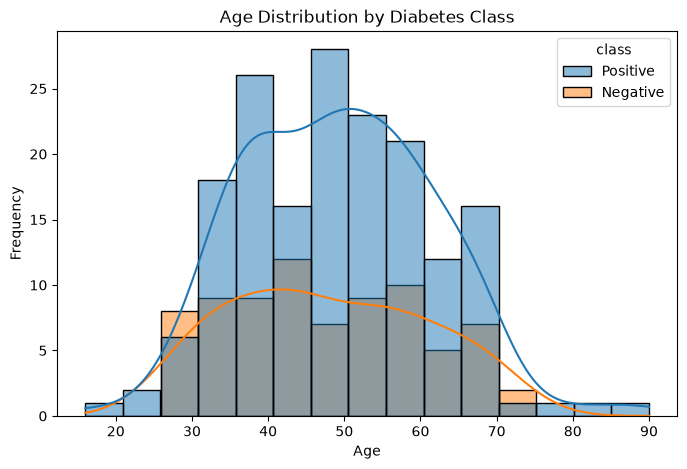

In [15]:
plt.figure(figsize=(8,5))
sns.histplot(data=df, x='Age', hue='class', bins=15, kde=True)
plt.title("Age Distribution by Diabetes Class")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

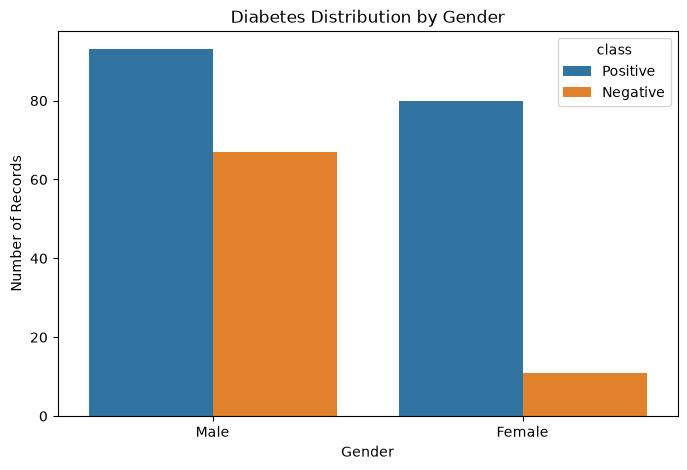

In [16]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='Gender', hue='class')
plt.title("Diabetes Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Records")
plt.show()

In [17]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Predefined diabetes questions and answers
qa_data = {
    "What is diabetes?": "Diabetes is a condition in which blood glucose levels become too high.",
    "What are the symptoms of diabetes?": "Common symptoms include increased thirst, frequent urination, tiredness and blurred vision.",
    "What are the risk factors?": "Risk factors include family history, age, physical inactivity and obesity.",
    "How can diabetes be prevented?": "Healthy eating, regular physical activity and routine health checkups can help reduce the risk of type 2 diabetes.",
    "What is type 1 diabetes?": "Type 1 diabetes is a condition in which the body produces little or no insulin.",
    "What is type 2 diabetes?": "Type 2 diabetes occurs when the body does not use insulin properly."
}

# Prepare questions for NLP
questions = list(qa_data.keys())

vectorizer = TfidfVectorizer()
question_vectors = vectorizer.fit_transform(questions)


# Health Assistant function
def health_assistant(user_question):
    user_vector = vectorizer.transform([user_question])
    scores = cosine_similarity(user_vector, question_vectors)

    best_match = scores.argmax()

    if scores[0][best_match] < 0.15:
        return "Sorry, I don't have information about this question."

    return qa_data[questions[best_match]]


# User-friendly menu
def run_health_assistant():
    print("\n===== GLUCOGUIDE AI HEALTH ASSISTANT =====")
    print("\nChoose a question from the menu:")

    for i, question in enumerate(questions, start=1):
        print(f"{i}. {question}")

    choice = input("\nEnter your choice (1-6): ").strip()

    if choice.isdigit() and 1 <= int(choice) <= len(questions):
        user_question = questions[int(choice) - 1]

        print("\nQuestion:", user_question)
        print("\nAnswer:", health_assistant(user_question))

    else:
        print("\nInvalid choice. Please select between 1 and 6.")


# Run Health Assistant
run_health_assistant()


===== GLUCOGUIDE AI HEALTH ASSISTANT =====

Choose a question from the menu:
1. What is diabetes?
2. What are the symptoms of diabetes?
3. What are the risk factors?
4. How can diabetes be prevented?
5. What is type 1 diabetes?
6. What is type 2 diabetes?



Question: What are the symptoms of diabetes?

Answer: Common symptoms include increased thirst, frequent urination, tiredness and blurred vision.


In [18]:
user_question = "What is diabetes?"
print(health_assistant(user_question))

Diabetes is a condition in which blood glucose levels become too high.


In [19]:
def risk_assessment():
    print("\n===== DIABETES RISK AWARENESS =====")

    age = int(input("Enter your age: "))

    symptoms = [
        "Frequent urination",
        "Excessive thirst",
        "Sudden weight loss",
        "Weakness",
        "Increased hunger",
        "Blurred vision",
        "Obesity"
    ]

    responses = []

    for symptom in symptoms:
        answer = input(f"{symptom}? (yes/no): ").strip().lower()
        responses.append(answer)

    count = responses.count("yes")

    print("\n===== ASSESSMENT RESULT =====")
    print("Age:", age)
    print("Reported factors:", count)

    if count == 0:
        print("No listed factors were reported.")
    else:
        print("Some diabetes-related symptoms or factors were reported.")

    print("\nThis is an educational awareness tool, not a medical diagnosis.")
    print("Please consult a healthcare professional for proper assessment.")

In [20]:

def health_information():
    print("\n===== DIABETES HEALTH INFORMATION =====", flush=True)
    print("1. What is Diabetes?", flush=True)
    print("2. Types of Diabetes", flush=True)
    print("3. Common Symptoms", flush=True)
    print("4. Prevention of Type 2 Diabetes", flush=True)

    choice = input("\nEnter your choice (1-4): ").strip()

    if choice == "1":
        print("\nDiabetes is a condition in which blood glucose levels become too high.")

    elif choice == "2":
        print("\nThe main types are Type 1, Type 2, and Gestational Diabetes.")

    elif choice == "3":
        print("\nCommon symptoms include increased thirst, frequent urination, tiredness and blurred vision.")

    elif choice == "4":
        print("\nHealthy eating, regular physical activity and routine health checkups can help reduce the risk of Type 2 diabetes.")

    else:
        print("\nInvalid choice. Please enter a number from 1 to 4.")


In [21]:
health_information()


===== DIABETES HEALTH INFORMATION =====
1. What is Diabetes?
2. Types of Diabetes
3. Common Symptoms
4. Prevention of Type 2 Diabetes

The main types are Type 1, Type 2, and Gestational Diabetes.


In [22]:
class HealthAssistant:

    def __init__(self, qa_data):
        self.qa_data = qa_data
        self.questions = list(qa_data.keys())
        self.vectorizer = TfidfVectorizer()
        self.question_vectors = self.vectorizer.fit_transform(self.questions)

    def ask_question(self, user_question):
        user_vector = self.vectorizer.transform([user_question])
        scores = cosine_similarity(user_vector, self.question_vectors)
        best_match = scores.argmax()

        if scores[0][best_match] < 0.15:
            return "Sorry, I don't have information about this question."

        return self.qa_data[self.questions[best_match]]

In [23]:
class RiskAssessment:

    def assess(self):
        print("\n===== DIABETES RISK AWARENESS =====")

        age = int(input("Enter your age: "))

        symptoms = [
            "Frequent urination",
            "Excessive thirst",
            "Sudden weight loss",
            "Weakness",
            "Increased hunger",
            "Blurred vision",
            "Obesity"
        ]

        count = 0

        for symptom in symptoms:
            answer = input(f"{symptom}? (yes/no): ").strip().lower()

            if answer == "yes":
                count += 1

        print("\n===== ASSESSMENT RESULT =====")
        print("Age:", age)
        print("Reported factors:", count)

        print("This is an educational awareness tool, not a medical diagnosis.")
        print("Consult a healthcare professional for proper assessment.")

In [24]:
risk = RiskAssessment()

risk.assess()


===== DIABETES RISK AWARENESS =====

===== ASSESSMENT RESULT =====
Age: 21
Reported factors: 3
This is an educational awareness tool, not a medical diagnosis.
Consult a healthcare professional for proper assessment.


In [25]:
class DataVisualizer:

    def show_class_distribution(self):
        sns.countplot(data=df, x='class')
        plt.title("Diabetes Class Distribution")
        plt.xlabel("Diabetes Class")
        plt.ylabel("Number of Records")
        plt.show()

    def show_age_distribution(self):
        plt.figure(figsize=(8,5))
        sns.histplot(data=df, x='Age', hue='class', bins=15, kde=True)
        plt.title("Age Distribution by Diabetes Class")
        plt.xlabel("Age")
        plt.ylabel("Frequency")
        plt.show()

    def show_gender_distribution(self):
        plt.figure(figsize=(8,5))
        sns.countplot(data=df, x='Gender', hue='class')
        plt.title("Diabetes Distribution by Gender")
        plt.xlabel("Gender")
        plt.ylabel("Number of Records")
        plt.show()

In [26]:

class GlucoGuideAI:

    def __init__(self):
        self.assistant = HealthAssistant(qa_data)
        self.risk = RiskAssessment()
        self.visualizer = DataVisualizer()

    def health_information(self):
        print("\n===== DIABETES HEALTH INFORMATION =====")
        print("1. What is Diabetes?")
        print("2. Types of Diabetes")
        print("3. Common Symptoms")
        print("4. Prevention of Type 2 Diabetes")

        choice = input("\nEnter your choice: ").strip()

        if choice == "1":
            print("Diabetes is a condition in which blood glucose levels become too high.")

        elif choice == "2":
            print("The main types are Type 1, Type 2 and Gestational Diabetes.")

        elif choice == "3":
            print("Common symptoms include increased thirst, frequent urination, tiredness and blurred vision.")

        elif choice == "4":
            print("Healthy eating, physical activity and routine health checkups can help reduce the risk of Type 2 diabetes.")

        else:
            print("Invalid choice.")

    def show_charts(self):
        print("\n===== DATA VISUALIZATION =====")
        print("1. Class Distribution")
        print("2. Age Distribution")
        print("3. Gender Distribution")

        choice = input("Enter your choice: ").strip()

        if choice == "1":
            self.visualizer.show_class_distribution()

        elif choice == "2":
            self.visualizer.show_age_distribution()

        elif choice == "3":
            self.visualizer.show_gender_distribution()

        else:
            print("Invalid choice.")

    def run(self):

        while True:

            print("\n================================")
            print("          GLUCOGUIDE AI")
            print("     Diabetes Awareness System")
            print("================================")

            print("1. Ask a Diabetes Question")
            print("2. Risk Assessment")
            print("3. Health Information")
            print("4. View Data Visualizations")
            print("5. Exit")

            choice = input("\nEnter your choice: ").strip()

            if choice == "1":

                print("\n===== HEALTH ASSISTANT =====")
                print("Choose a diabetes-related question:")

                for i, question in enumerate(self.assistant.questions, start=1):
                    print(f"{i}. {question}")

                question_choice = input("\nEnter your choice (1-6): ").strip()

                if question_choice.isdigit() and 1 <= int(question_choice) <= len(self.assistant.questions):

                    question = self.assistant.questions[int(question_choice) - 1]
                    answer = self.assistant.ask_question(question)

                    print("\nQuestion:", question)
                    print("\nAnswer:", answer)

                else:
                    print("\nInvalid choice. Please select between 1 and 6.")

            elif choice == "2":
                self.risk.assess()

            elif choice == "3":
                self.health_information()

            elif choice == "4":
                self.show_charts()

            elif choice == "5":
                print("\nThank you for using GlucoGuide AI!")
                break

            else:
                print("\nInvalid choice. Please try again.")



          GLUCOGUIDE AI
     Diabetes Awareness System
1. Ask a Diabetes Question
2. Risk Assessment
3. Health Information
4. View Data Visualizations
5. Exit

===== DATA VISUALIZATION =====
1. Class Distribution
2. Age Distribution
3. Gender Distribution


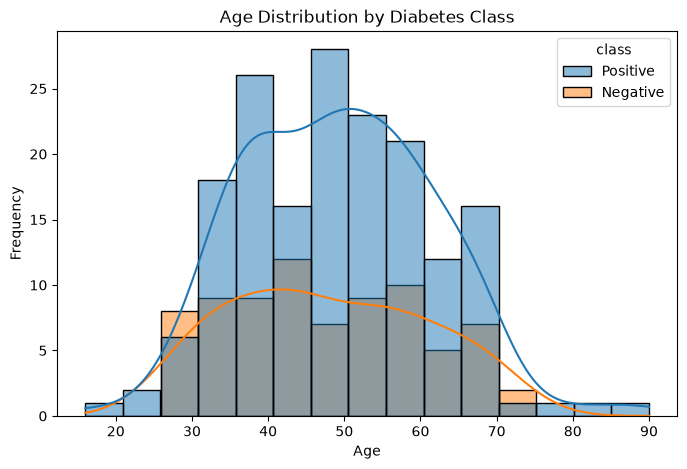


          GLUCOGUIDE AI
     Diabetes Awareness System
1. Ask a Diabetes Question
2. Risk Assessment
3. Health Information
4. View Data Visualizations
5. Exit

Thank you for using GlucoGuide AI!


In [27]:
app = GlucoGuideAI()

app.run()

In [28]:
choice = input("Enter your choice: ")
print("You selected:", choice)

You selected: 3


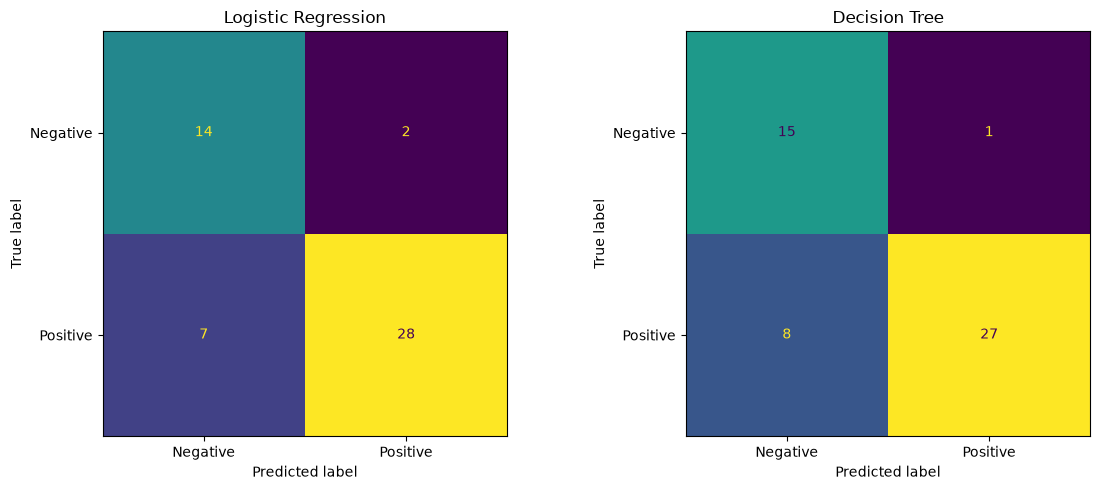

In [29]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_lr = confusion_matrix(y_test, y_pred_lr)
ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=["Negative", "Positive"]
).plot(ax=axes[0], colorbar=False)

axes[0].set_title("Logistic Regression")

cm_dt = confusion_matrix(y_test, y_pred_dt)
ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=["Negative", "Positive"]
).plot(ax=axes[1], colorbar=False)

axes[1].set_title("Decision Tree")

plt.tight_layout()
plt.show()

In [30]:
class RiskAssessment:

    def assess(self):
        print("\n===== DIABETES RISK AWARENESS =====")

        while True:
            try:
                age = int(input("Enter your age: "))

                if age <= 0 or age > 120:
                    print("Please enter a valid age.")
                    continue

                break

            except ValueError:
                print("Please enter age in numbers.")

        symptoms = [
            "Frequent urination",
            "Excessive thirst",
            "Sudden weight loss",
            "Weakness",
            "Increased hunger",
            "Blurred vision",
            "Obesity"
        ]

        count = 0

        for symptom in symptoms:
            while True:
                answer = input(f"{symptom}? (yes/no): ").strip().lower()

                if answer in ["yes", "no"]:
                    break

                print("Please enter yes or no.")

            if answer == "yes":
                count += 1

        print("\n===== ASSESSMENT RESULT =====")
        print("Age:", age)
        print("Reported factors:", count)
        print("This is educational information, not a medical diagnosis.")
        print("Consult a healthcare professional for proper assessment.")

In [31]:
from abc import ABC, abstractmethod

class HealthModule(ABC):

    @abstractmethod
    def display_info(self):
        pass


class HealthInfoModule(HealthModule):

    def display_info(self):
        print("This module provides diabetes health information.")


class VisualizationModule(HealthModule):

    def display_info(self):
        print("This module displays diabetes data charts.")


class RiskInfoModule(HealthModule):

    def display_info(self):
        print("This module provides educational risk awareness.")


modules = [
    HealthInfoModule(),
    VisualizationModule(),
    RiskInfoModule()
]

for module in modules:
    module.display_info()

This module provides diabetes health information.
This module displays diabetes data charts.
This module provides educational risk awareness.


In [32]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_dt)
    ],
    "Precision": [
        precision_score(y_test, y_pred_lr, zero_division=0),
        precision_score(y_test, y_pred_dt, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_pred_lr, zero_division=0),
        recall_score(y_test, y_pred_dt, zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred_lr, zero_division=0),
        f1_score(y_test, y_pred_dt, zero_division=0)
    ]
})

display(results.round(3))

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.824,0.933,0.800,0.862
1,Decision Tree,0.824,0.964,0.771,0.857


In [36]:
print("Original Dataset Shape:", df.shape)
print("Duplicate Rows:", df.duplicated().sum())
print("Missing Values:", df.isnull().sum().sum())
print(df['class'].value_counts())

Original Dataset Shape: (251, 17)
Duplicate Rows: 0
Missing Values: 0
class
Positive    173
Negative     78
Name: count, dtype: int64


In [37]:
print("Dataset Shape:", df.shape)
print("Duplicate Rows:", df.duplicated().sum())
print("Missing Values:", df.isnull().sum().sum())

print("\nClass Distribution:")
print(df['class'].value_counts())

Dataset Shape: (251, 17)
Duplicate Rows: 0
Missing Values: 0

Class Distribution:
class
Positive    173
Negative     78
Name: count, dtype: int64


In [38]:
import os

print(os.listdir())

['diabetes_data.csv', 'GlucoGuide.ipynb']


In [39]:
original_df = pd.read_csv("diabetes_data.csv")

print("Original Shape:", original_df.shape)
print("Exact Duplicate Rows:", original_df.duplicated().sum())
print("Shape After Removing Duplicates:", original_df.drop_duplicates().shape)

Original Shape: (520, 17)
Exact Duplicate Rows: 269
Shape After Removing Duplicates: (251, 17)


Project Introduction



Importing Libraries



Dataset Loading



Dataset Exploration



Data Cleaning



Data Preprocessing



Machine Learning Models



Model Evaluation



Data Visualization



NLP Health Assistant



Risk Assessment



Health Information



OOP Implementation



Main Console Application



Application Testing

Project Conclusion

GlucoGuide AI is a Python-based diabetes awareness system. It provides a text-based health assistant, educational risk awareness, data visualizations, and machine learning model comparison. The system uses the UCI Early Stage Diabetes Risk Prediction dataset. It helps users understand diabetes-related information but does not provide medical diagnosis or treatment.

In [40]:
print("Logistic Regression Training Accuracy:",
      lr_model.score(X_train, y_train))

print("Decision Tree Training Accuracy:",
      dt_model.score(X_train, y_train))

Logistic Regression Training Accuracy: 0.925
Decision Tree Training Accuracy: 1.0


In [ ]:
import sys
print(sys.version)

3.13.17 (tags/v3.13.17:64e080d, Oct 21 2026, 14:08:53) [MSC v.1944 64 bit (AMD64)]


In [ ]:
import pandas, numpy, matplotlib, seaborn, sklearn, notebook

print("pandas==", pandas.__version__)
print("numpy==", numpy.__version__)
print("matplotlib==", matplotlib.__version__)
print("seaborn==", seaborn.__version__)
print("scikit-learn==", sklearn.__version__)
print("notebook==", notebook.__version__)

pandas== 3.1.1
numpy== 2.5.4
matplotlib== 3.11.2
seaborn== 0.13.2
scikit-learn== 1.9.1
notebook== 7.6.5
